# 01. Comprehensive Dataset Audit
## Rheumatoid Arthritis Classification System

### Executive Purpose
This notebook performs an exhaustive forensic audit of the raw clinical dataset (`Rheumatic and Autoimmune Disease Dataset.xlsx`). It investigates:
1. Workbook structure, sheets, dimensional shape, and data types.
2. Clinical diagnosis distributions across the cohort.
3. Missingness across demographic and laboratory biomarkers.
4. Duplicate records (exact and feature-only subsets).
5. Numerical distributions, ranges, and potential statistical outliers.
6. Categorical serology distributions and whitespace/encoding anomalies.
7. **Sequential row ordering analysis** (detecting contiguous diagnosis blocks).
8. Fundamental clinical limitations and risks (e.g., absence of MRN/Patient ID, cross-sectional nature).
9. Generation and export of machine-readable (`dataset_audit_report.json`) and human-readable (`dataset_audit_summary.md`) audit reports.


In [1]:
import sys
import os
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Add project root to sys.path
root = Path("..").resolve() if Path("..").resolve().name == "RA_Project" else Path(".").resolve()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.data_audit import inspect_sheets, audit_dataset, generate_audit_report, detect_diagnosis_blocks

print(f"Project root resolved to: {root}")


Project root resolved to: D:\PRJ 1 Sem 5\RA_Project


## 1. Raw Workbook Inspection
We verify that the raw Excel workbook exists at `data/raw/Rheumatic and Autoimmune Disease Dataset.xlsx` and inspect its sheets.


In [2]:
raw_excel_path = root / "data" / "raw" / "Rheumatic and Autoimmune Disease Dataset.xlsx"
assert raw_excel_path.exists(), f"Raw dataset not found at {raw_excel_path}"

sheets = inspect_sheets(raw_excel_path)
print(f"Raw workbook: {raw_excel_path.name}")
print(f"Workbook sheets: {sheets}")

# Load raw dataset into pandas DataFrame
df_raw = pd.read_excel(raw_excel_path)
print(f"\nDataset Dimensions: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
assert df_raw.shape == (12085, 15), f"Unexpected shape {df_raw.shape}, expected (12085, 15)"


Raw workbook: Rheumatic and Autoimmune Disease Dataset.xlsx
Workbook sheets: ['Sheet1']



Dataset Dimensions: 12,085 rows × 15 columns


In [3]:
# Display column schema and initial rows
print("Column Data Types:")
print(df_raw.dtypes)

print("\nFirst 5 Records:")
df_raw.head()


Column Data Types:
Age             int64
Gender         object
ESR           float64
CRP           float64
RF            float64
Anti-CCP      float64
HLA-B27        object
ANA            object
Anti-Ro        object
Anti-La        object
Anti-dsDNA     object
Anti-Sm        object
C3            float64
C4            float64
Disease        object
dtype: object

First 5 Records:


,Age,Gender,ESR,CRP,RF,Anti-CCP,HLA-B27,ANA,Anti-Ro,Anti-La,Anti-dsDNA,Anti-Sm,C3,C4,Disease
0,70,Male,39.0,18.6,34.2,29.9,Positive,Negative,Positive,Negative,Positive,Positive,NaN,27.0,Rheumatoid Arthritis
1,39,Female,26.0,21.7,35.5,28.9,Negative,NaN,Positive,NaN,Positive,NaN,100.0,66.0,Rheumatoid Arthritis
2,36,Female,41.0,15.6,21.3,21.3,Negative,Negative,NaN,Positive,Negative,NaN,158.0,12.0,Rheumatoid Arthritis
3,35,Male,43.0,23.4,26.0,39.0,NaN,NaN,Positive,Positive,NaN,NaN,119.0,41.0,Rheumatoid Arthritis
4,37,Female,30.0,NaN,38.1,30.8,Positive,Negative,Positive,Negative,Positive,Negative,144.0,49.0,Rheumatoid Arthritis


## 2. Diagnosis Distribution
We examine the distribution of the original `Disease` column across the 12,085 records.


Diagnosis Distribution:


,Record Count,Percentage (%)
Disease,,
Rheumatoid Arthritis,2848,23.57
Ankylosing Spondylitis,2127,17.60
Sjögren's Syndrome,1852,15.32
Psoriatic Arthritis,1783,14.75
Normal,1604,13.27
Systemic Lupus Erythematosus,1355,11.21
Reactive Arthritis,516,4.27


C:\Users\anjan\AppData\Local\Temp\ipykernel_20248\846596036.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=diag_summary['Record Count'], y=diag_summary.index, palette=colors)


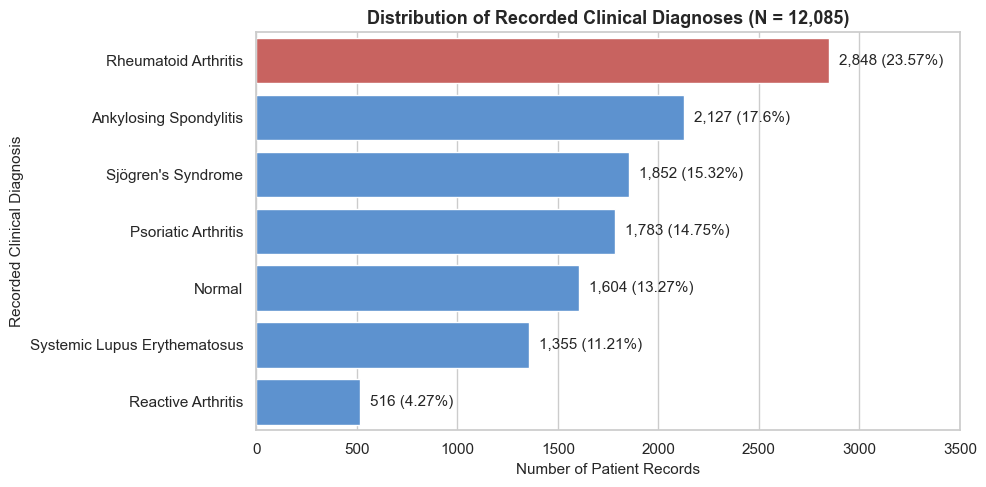

In [4]:
diagnosis_counts = df_raw['Disease'].value_counts(dropna=False)
diagnosis_pct = df_raw['Disease'].value_counts(normalize=True) * 100

diag_summary = pd.DataFrame({
    'Record Count': diagnosis_counts,
    'Percentage (%)': diagnosis_pct.round(2)
})
print("Diagnosis Distribution:")
display(diag_summary)

# Visualize diagnosis breakdown
plt.figure(figsize=(10, 5))
colors = ['#d9534f' if d == 'Rheumatoid Arthritis' else '#4a90e2' for d in diag_summary.index]
ax = sns.barplot(x=diag_summary['Record Count'], y=diag_summary.index, palette=colors)
plt.title("Distribution of Recorded Clinical Diagnoses (N = 12,085)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Patient Records", fontsize=11)
plt.ylabel("Recorded Clinical Diagnosis", fontsize=11)
for i, v in enumerate(diag_summary['Record Count']):
    ax.text(v + 50, i, f"{v:,} ({diag_summary['Percentage (%)'].iloc[i]}%)", va='center', fontweight='medium')
plt.xlim(0, 3500)
plt.tight_layout()
plt.show()


## 3. Row Sequence Analysis & Block Ordering Detection
> **CRITICAL ARCHITECTURAL FINDING**:
> We analyze the sequential order of records in the raw workbook to check whether cases appear randomly or in grouped clusters.


Contiguous Diagnosis Blocks in Raw Workbook Sequence:


,diagnosis,start_index,end_index,block_length,Cumulative %
0,Rheumatoid Arthritis,0,2847,2848,23.57
1,Reactive Arthritis,2848,3363,516,27.84
2,Ankylosing Spondylitis,3364,5490,2127,45.44
3,Sjögren's Syndrome,5491,7342,1852,60.76
4,Systemic Lupus Erythematosus,7343,8697,1355,71.97
5,Normal,8698,10301,1604,85.25
6,Psoriatic Arthritis,10302,12084,1783,100.00


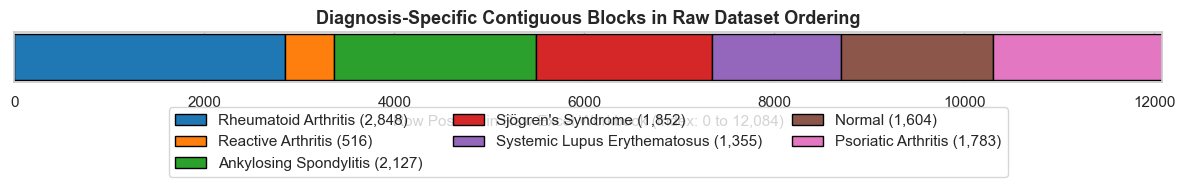

In [5]:
blocks = detect_diagnosis_blocks(df_raw, disease_col="Disease")
blocks_df = pd.DataFrame(blocks)
blocks_df['Cumulative %'] = (blocks_df['block_length'].cumsum() / len(df_raw) * 100).round(2)

print("Contiguous Diagnosis Blocks in Raw Workbook Sequence:")
display(blocks_df)

# Visualizing the contiguous block layout
plt.figure(figsize=(12, 2.5))
palette = sns.color_palette("tab10", len(blocks))
left = 0
for idx, row in blocks_df.iterrows():
    width = row['block_length']
    plt.barh(0, width, left=left, color=palette[idx], label=f"{row['diagnosis']} ({width:,})", edgecolor='black')
    left += width

plt.yticks([])
plt.xlabel("Row Position in Raw Excel Workbook (Index: 0 to 12,084)", fontsize=11)
plt.title("Diagnosis-Specific Contiguous Blocks in Raw Dataset Ordering", fontsize=13, fontweight='bold')
plt.legend(bbox_to_anchor=(0.5, -0.35), loc='upper center', ncol=3, frameon=True)
plt.xlim(0, 12085)
plt.tight_layout()
plt.show()


## 4. Completeness and Missing Value Audit
We quantify missing values across all columns and assess patient-level co-missingness.


Completeness by Column:


,Data Type,Non-Null Count,Missing Count,Missing Percentage (%)
Anti-Sm,object,6888,5197,43.0
Anti-dsDNA,object,7372,4713,39.0
ANA,object,8339,3746,31.0
Anti-CCP,float64,8822,3263,27.0
Anti-La,object,9064,3021,25.0
Anti-Ro,object,9185,2900,24.0
CRP,float64,9668,2417,20.0
C4,float64,10031,2054,17.0
HLA-B27,object,10151,1934,16.0
C3,float64,10393,1692,14.0


C:\Users\anjan\AppData\Local\Temp\ipykernel_20248\904557703.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cols_with_missing['Missing Percentage (%)'], y=cols_with_missing.index, palette="mako")


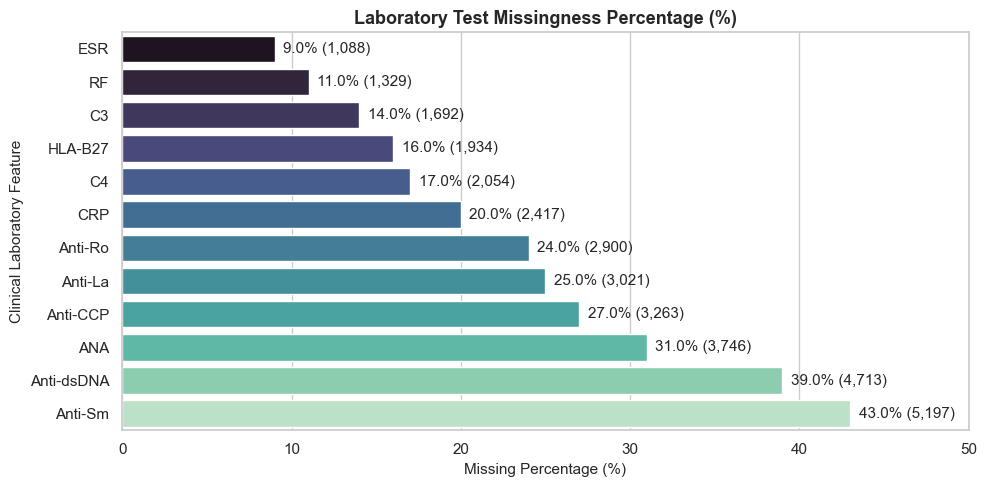

In [6]:
missing_counts = df_raw.isnull().sum()
missing_pcts = (missing_counts / len(df_raw)) * 100

missing_df = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Non-Null Count': df_raw.notnull().sum(),
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_pcts.round(2)
}).sort_values('Missing Count', ascending=False)

print("Completeness by Column:")
display(missing_df)

# Plot missingness
plt.figure(figsize=(10, 5))
cols_with_missing = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Percentage (%)')
sns.barplot(x=cols_with_missing['Missing Percentage (%)'], y=cols_with_missing.index, palette="mako")
plt.title("Laboratory Test Missingness Percentage (%)", fontsize=13, fontweight='bold')
plt.xlabel("Missing Percentage (%)", fontsize=11)
plt.ylabel("Clinical Laboratory Feature", fontsize=11)
for i, v in enumerate(cols_with_missing['Missing Percentage (%)']):
    plt.text(v + 0.5, i, f"{v:.1f}% ({cols_with_missing['Missing Count'].iloc[i]:,})", va='center')
plt.xlim(0, 50)
plt.tight_layout()
plt.show()


In [7]:
# Assess missing lab tests per patient row
lab_cols = [c for c in df_raw.columns if c not in ['Age', 'Gender', 'Disease']]
missing_per_patient = df_raw[lab_cols].isnull().sum(axis=1)

print("Distribution of Missing Laboratory Measurements Per Patient:")
patient_missing_dist = missing_per_patient.value_counts().sort_index()
patient_missing_table = pd.DataFrame({
    'Missing Lab Tests Count': patient_missing_dist.index,
    'Patient Count': patient_missing_dist.values,
    'Cohort %': (patient_missing_dist.values / len(df_raw) * 100).round(2)
})
display(patient_missing_table)

complete_patients = (missing_per_patient == 0).sum()
print(f"\nPatients with ALL 12 laboratory tests recorded: {complete_patients:,} ({(complete_patients/len(df_raw))*100:.2f}%)")
print(f"Patients with 1 or more missing lab tests: {len(df_raw) - complete_patients:,} ({((len(df_raw) - complete_patients)/len(df_raw))*100:.2f}%)")
print("-> CONCLUSION: Listwise deletion (dropna) would destroy 96.3% of the dataset!")


Distribution of Missing Laboratory Measurements Per Patient:


,Missing Lab Tests Count,Patient Count,Cohort %
0,0,452,3.74
1,1,1796,14.86
2,2,3204,26.51
3,3,3191,26.40
4,4,2127,17.60
5,5,919,7.60
6,6,313,2.59
7,7,69,0.57
8,8,13,0.11
9,9,1,0.01



Patients with ALL 12 laboratory tests recorded: 452 (3.74%)
Patients with 1 or more missing lab tests: 11,633 (96.26%)
-> CONCLUSION: Listwise deletion (dropna) would destroy 96.3% of the dataset!


## 5. Duplicate Row Audit
We check for exact duplicates across all 15 columns, as well as feature-only duplicates.


In [8]:
exact_dups = df_raw.duplicated().sum()
feature_dups = df_raw.duplicated(subset=[c for c in df_raw.columns if c != 'Disease']).sum()

print(f"Exact Duplicate Rows across all 15 columns: {exact_dups}")
print(f"Feature Duplicates (identical labs/demographics, ignoring Disease): {feature_dups}")
assert exact_dups == 0, "Warning: Exact duplicate rows detected in raw dataset!"


Exact Duplicate Rows across all 15 columns: 0
Feature Duplicates (identical labs/demographics, ignoring Disease): 0


## 6. Numerical & Categorical Feature Audits
We examine statistical summaries, ranges, zero values, IQR outliers, and whitespace anomalies.


In [9]:
num_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
num_stats = df_raw[num_cols].describe().T
num_stats['zero_count'] = [(df_raw[col] == 0).sum() for col in num_cols]
num_stats['negative_count'] = [(df_raw[col] < 0).sum() for col in num_cols]

print("Numerical Features Summary:")
display(num_stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'zero_count', 'negative_count']])


Numerical Features Summary:


,count,mean,std,min,25%,50%,75%,max,zero_count,negative_count
Age,12085.0,49.905751,17.649957,20.0,35.0,50.0,65.0,80.0,0,0
ESR,10997.0,24.214331,14.368259,0.0,10.0,28.0,36.0,49.0,260,0
CRP,9668.0,13.325010,10.392953,0.1,1.9,15.6,22.6,30.0,0,0
RF,10756.0,19.685180,11.517631,0.0,9.7,19.2,29.7,40.0,11,0
Anti-CCP,8822.0,19.579245,11.601712,0.0,9.5,19.0,29.6,40.0,12,0
C3,10393.0,131.910324,36.425864,50.0,105.0,133.0,161.0,205.0,0,0
C4,10031.0,38.178547,20.050244,5.0,21.0,38.0,55.0,74.0,0,0


In [10]:
cat_cols = df_raw.select_dtypes(include=['object']).columns.tolist()
for c in cat_cols:
    val_counts = df_raw[c].value_counts(dropna=False).to_dict()
    has_ws = any(str(v) != str(v).strip() for v in df_raw[c].dropna().unique())
    print(f"Feature: {c} (Whitespace anomaly: {has_ws}) -> {val_counts}")


Feature: Gender (Whitespace anomaly: False) -> {'Male': 6151, 'Female': 5934}
Feature: HLA-B27 (Whitespace anomaly: False) -> {'Positive': 6231, 'Negative': 3920, nan: 1934}
Feature: ANA (Whitespace anomaly: False) -> {'Positive': 5248, nan: 3746, 'Negative': 3091}
Feature: Anti-Ro (Whitespace anomaly: False) -> {'Positive': 5292, 'Negative': 3893, nan: 2900}
Feature: Anti-La (Whitespace anomaly: False) -> {'Positive': 5305, 'Negative': 3759, nan: 3021}
Feature: Anti-dsDNA (Whitespace anomaly: False) -> {nan: 4713, 'Positive': 4077, 'Negative': 3295}
Feature: Anti-Sm (Whitespace anomaly: False) -> {nan: 5197, 'Positive': 3759, 'Negative': 3129}
Feature: Disease (Whitespace anomaly: False) -> {'Rheumatoid Arthritis': 2848, 'Ankylosing Spondylitis': 2127, "Sjögren's Syndrome": 1852, 'Psoriatic Arthritis': 1783, 'Normal': 1604, 'Systemic Lupus Erythematosus': 1355, 'Reactive Arthritis': 516}


## 7. Machine-Readable & Human-Readable Report Generation
We invoke `generate_audit_report` to save the official audit artifacts to `data/reports/`.


In [11]:
json_report_path = root / "data" / "reports" / "dataset_audit_report.json"
md_report_path = root / "data" / "reports" / "dataset_audit_summary.md"

audit_results = generate_audit_report(
    raw_path=raw_excel_path,
    output_json_path=json_report_path,
    output_md_path=md_report_path
)

print(f"Audit JSON report written to: {json_report_path}")
print(f"Audit Markdown summary written to: {md_report_path}")

assert json_report_path.exists() and json_report_path.stat().st_size > 0
assert md_report_path.exists() and md_report_path.stat().st_size > 0
print("Dataset audit complete and all artifacts verified.")


Audit JSON report written to: D:\PRJ 1 Sem 5\RA_Project\data\reports\dataset_audit_report.json
Audit Markdown summary written to: D:\PRJ 1 Sem 5\RA_Project\data\reports\dataset_audit_summary.md
Dataset audit complete and all artifacts verified.
